# Quantile models: Linear Quantile Regression, quantile XGBoost, quantile LightGBM

Research question 2: **can a model forecast a "safe" level of demand, not just one number?**

A quantile model forecasts the level that demand stays below with probability $\tau$.
Example: $\tau$ = 0.8 is an order that is enough in about 8 out of 10 weeks.

Three models, each for $\tau$ = 0.3, 0.4, ..., 0.9 (same folds and features as notebooks 04 and 05):
- **Linear QR** (statsmodels), trained on a sample of 300,000 rows because it is slow
- **Quantile LightGBM**, one model per $\tau$
- **Quantile XGBoost**, one model for all 7 levels

How we check them:
- **pinball loss** (lower is better)
- **coverage**: % of weeks where the actual orders were below the forecast, should be close to $\tau$

Training takes about 70 min. Set `RUN_TRAINING = False` to load the saved predictions instead.

In [1]:
import sys
sys.path.append('..')
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
import statsmodels.api as sm

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from src.features import build_dataset, FEATURES, HISTORY_COLS, TARGET_WEEK_COLS
from src.folds import ORIGINS, split_fold
from src.metrics import all_metrics, pinball, diebold_mariano
from src.simulation import TAUS
from src.plot_settings import set_ieee_style, save_fig, ONE_COL, TWO_COL

set_ieee_style()
pd.set_option('display.max_columns', 30)

RUN_TRAINING = True
SEED = 42

# hide long library warnings
warnings.filterwarnings('ignore')

print(TAUS)

[0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


## 1. Load data

In [2]:
df = pd.read_parquet('../data/processed/clean.parquet')
hist = pd.read_parquet('../data/processed/history_features.parquet')
data = build_dataset(df, hist)

for col in ['center_id', 'meal_id', 'city_code', 'region_code']:
    data[col] = data[col].astype('category')

print(data.shape)

(4407292, 32)


## 2. Training functions

Each function trains the models of one fold and returns the forecasts: one column per $\tau$.

In [3]:
def inner_split(train, origin):
    # validation = the last 10 training weeks
    return split_fold(train, origin - 10)


def to_orders(log_pred):
    return np.clip(np.expm1(log_pred), 0, None)


def crossing_rate(q):
    # % of rows where a higher tau got a LOWER forecast than the tau before it
    return np.mean(np.any(np.diff(q, axis=1) < 0, axis=1)) * 100

### Linear Quantile Regression

Same inputs and preparation as the Linear Regression baseline in notebook 04.

In [4]:
qr_numeric = ['h'] + HISTORY_COLS + TARGET_WEEK_COLS + ['price_vs_mean', 'price_vs_last', 'op_area']
qr_categorical = ['center_type', 'category', 'cuisine', 'region_code']
QR_SAMPLE = 300_000

def train_linear_qr(train, test, origin):
    sample = train.sample(min(QR_SAMPLE, len(train)), random_state=SEED)

    numeric = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    prep = ColumnTransformer([('num', numeric, qr_numeric),
                              ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), qr_categorical)])
    X_train = sm.add_constant(prep.fit_transform(sample[qr_numeric + qr_categorical]))
    X_test = sm.add_constant(prep.transform(test[qr_numeric + qr_categorical]), has_constant='add')

    forecasts = []
    for tau in TAUS:
        result = sm.QuantReg(sample['log_orders'].values, X_train).fit(q=tau, max_iter=2000)
        log_pred = np.clip(X_test @ result.params, 0, train['log_orders'].max())
        forecasts.append(np.expm1(log_pred))
    return np.column_stack(forecasts), '-'

### Quantile LightGBM

Settings from notebook 05. The number of trees is chosen by early stopping for every $\tau$.

In [5]:
best_05 = pd.read_csv('../results/tables/05_best_params.csv')

def lightgbm_settings(origin):
    row = best_05[(best_05['origin'] == origin) & (best_05['model'] == 'LightGBM')].iloc[0]
    return {'num_leaves': int(row['num_leaves']), 'min_child_samples': int(row['min_child_samples'])}


def train_lightgbm_quantile(train, test, origin):
    inner_train, val = inner_split(train, origin)
    params = lightgbm_settings(origin)

    forecasts = []
    trees = []
    for tau in TAUS:
        model = lgb.LGBMRegressor(objective='quantile', alpha=tau, n_estimators=3000, learning_rate=0.05,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                  random_state=SEED, verbose=-1, **params)
        model.fit(inner_train[FEATURES], inner_train['log_orders'],
                  eval_set=[(val[FEATURES], val['log_orders'])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        n_trees = model.best_iteration_

        final = lgb.LGBMRegressor(objective='quantile', alpha=tau, n_estimators=n_trees, learning_rate=0.05,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                  random_state=SEED, verbose=-1, **params)
        final.fit(train[FEATURES], train['log_orders'])
        forecasts.append(to_orders(final.predict(test[FEATURES])))
        trees.append(n_trees)
    return np.column_stack(forecasts), trees

### Quantile XGBoost

One model for all 7 levels. Learning rate 0.1 (not 0.05) to halve the training time.

In [6]:
xgb_settings = dict(objective='reg:quantileerror', quantile_alpha=np.array(TAUS), learning_rate=0.1,
                    max_depth=8, min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
                    tree_method='hist', enable_categorical=True, max_cat_to_onehot=1,
                    random_state=SEED, n_jobs=-1)

def train_xgboost_quantile(train, test, origin):
    inner_train, val = inner_split(train, origin)
    model = xgb.XGBRegressor(n_estimators=3000, early_stopping_rounds=50, **xgb_settings)
    model.fit(inner_train[FEATURES], inner_train['log_orders'],
              eval_set=[(val[FEATURES], val['log_orders'])], verbose=False)
    n_trees = model.best_iteration + 1

    final = xgb.XGBRegressor(n_estimators=n_trees, **xgb_settings)
    final.fit(train[FEATURES], train['log_orders'], verbose=False)
    return to_orders(final.predict(test[FEATURES])), n_trees

## 3. Train and test on all folds

In [7]:
models = {
    'Linear QR': train_linear_qr,
    'XGBoost': train_xgboost_quantile,
    'LightGBM': train_lightgbm_quantile,
}

if RUN_TRAINING:
    predictions = []
    train_info = []

    for origin in ORIGINS:
        train, test = split_fold(data, origin)
        pred_table = test[['series_id', 'center_id', 'meal_id', 'week', 'h', 'num_orders']].copy()
        pred_table['origin'] = origin

        for name, train_model in models.items():
            start = time.time()
            q, trees = train_model(train, test, origin)

            crossing = crossing_rate(q)
            q = np.sort(q, axis=1)          # fix crossing: the forecasts must go up with tau
            for i, tau in enumerate(TAUS):
                pred_table[f'{name} q{tau}'] = q[:, i]

            minutes = (time.time() - start) / 60
            train_info.append({'origin': origin, 'model': name, 'trees': str(trees),
                               'crossing rows %': round(crossing, 2), 'minutes': round(minutes, 1)})
            print(f'origin {origin}  {name:9s} trees={trees}  crossing={crossing:.2f}%  ({minutes:.1f} min)')

        predictions.append(pred_table)

    predictions = pd.concat(predictions, ignore_index=True)
    predictions['center_id'] = predictions['center_id'].astype(int)
    predictions['meal_id'] = predictions['meal_id'].astype(int)
    predictions.to_parquet('../data/processed/predictions_quantiles.parquet', index=False)
    train_info = pd.DataFrame(train_info)
    train_info.to_csv('../results/tables/06_training_info.csv', index=False)
else:
    predictions = pd.read_parquet('../data/processed/predictions_quantiles.parquet')
    train_info = pd.read_csv('../results/tables/06_training_info.csv')

train_info

origin 115  Linear QR trees=-  crossing=0.00%  (0.9 min)


origin 115  XGBoost   trees=222  crossing=0.00%  (10.7 min)


origin 115  LightGBM  trees=[157, 103, 232, 299, 324, 209, 200]  crossing=28.27%  (7.5 min)


origin 125  Linear QR trees=-  crossing=0.00%  (1.0 min)


origin 125  XGBoost   trees=227  crossing=0.00%  (11.9 min)


origin 125  LightGBM  trees=[150, 130, 244, 252, 192, 181, 196]  crossing=25.23%  (7.3 min)


origin 135  Linear QR trees=-  crossing=0.00%  (0.8 min)


origin 135  XGBoost   trees=187  crossing=0.00%  (10.9 min)


origin 135  LightGBM  trees=[341, 556, 585, 609, 125, 115, 120]  crossing=23.85%  (7.1 min)


,origin,model,trees,crossing rows %,minutes
0,115,Linear QR,-,0.00,0.9
1,115,XGBoost,222,0.00,10.7
2,115,LightGBM,"[157, 103, 232, 299, 324, 209, 200]",28.27,7.5
3,125,Linear QR,-,0.00,1.0
4,125,XGBoost,227,0.00,11.9
5,125,LightGBM,"[150, 130, 244, 252, 192, 181, 196]",25.23,7.3
6,135,Linear QR,-,0.00,0.8
7,135,XGBoost,187,0.00,10.9
8,135,LightGBM,"[341, 556, 585, 609, 125, 115, 120]",23.85,7.1


## 4. Results

The point LightGBM forecast from notebook 05 is added as a reference.

In [8]:
keys = ['series_id', 'week', 'origin']
point = pd.read_parquet('../data/processed/predictions_trees.parquet')[keys + ['LightGBM']]
point = point.rename(columns={'LightGBM': 'LightGBM point'})
qpred = predictions.merge(point, on=keys, how='inner')
print(len(predictions), len(qpred))      # same rows

q_models = ['Linear QR', 'XGBoost', 'LightGBM']
model_order = q_models + ['LightGBM point']

rows = []
for origin in ORIGINS:
    fold = qpred[qpred['origin'] == origin]
    y = fold['num_orders'].values
    for tau in TAUS:
        for name in model_order:
            q = fold['LightGBM point'].values if name == 'LightGBM point' else fold[f'{name} q{tau}'].values
            rows.append({'origin': origin, 'tau': tau, 'model': name,
                         'pinball': pinball(y, q, tau), 'coverage': np.mean(y <= q) * 100})
qres = pd.DataFrame(rows)

98475 98475


### Pinball loss (mean of 3 folds, in orders)

In [9]:
pinball_table = qres.groupby(['tau', 'model'])['pinball'].mean().unstack()[model_order]
pinball_table.loc['mean'] = pinball_table.mean()
pinball_table.round(2)

model,Linear QR,XGBoost,LightGBM,LightGBM point
tau,,,,
0.3,31.42,29.28,29.21,31.38
0.4,36.21,33.38,33.21,33.53
0.5,38.86,35.31,35.00,35.68
0.6,39.20,35.24,35.00,37.83
0.7,37.07,32.85,33.02,39.98
0.8,31.76,27.82,28.12,42.13
0.9,21.97,19.22,19.54,44.28
mean,33.78,30.44,30.44,37.83


In [10]:
# gain of quantile LightGBM over the point forecast, in %
gain = (pinball_table['LightGBM point'] - pinball_table['LightGBM']) / pinball_table['LightGBM point'] * 100
gain.round(1)

tau
0.3      6.9
0.4      1.0
0.5      1.9
0.6      7.5
0.7     17.4
0.8     33.3
0.9     55.9
mean    19.5
dtype: float64

### Coverage (should be close to $\tau$ x 100)

In [11]:
coverage_table = qres.groupby(['tau', 'model'])['coverage'].mean().unstack()[model_order]
coverage_table.round(1)

model,Linear QR,XGBoost,LightGBM,LightGBM point
tau,,,,
0.3,29.8,30.4,30.6,45.9
0.4,40.0,40.0,40.2,45.9
0.5,50.0,49.7,49.3,45.9
0.6,60.1,59.0,58.0,45.9
0.7,69.8,68.6,67.5,45.9
0.8,79.8,77.9,77.4,45.9
0.9,89.7,88.2,87.4,45.9


In [12]:
# mean distance from the target coverage, in points
calibration_error = (coverage_table[q_models].sub(np.array(TAUS) * 100, axis=0)).abs().mean()
calibration_error.round(2)

model
Linear QR    0.15
XGBoost      1.00
LightGBM     1.60
dtype: float64

### Diebold-Mariano test

Weekly pinball loss, 30 test weeks. Negative = the first model is better.

In [13]:
qpred['test_week'] = qpred['origin'].astype(str) + '_' + qpred['week'].astype(str)

def weekly_pinball(column, tau):
    y = qpred['num_orders']
    diff = y - qpred[column]
    loss = np.maximum(tau * diff, (tau - 1) * diff)
    return loss.groupby(qpred['test_week']).mean()

dm_rows = []
for tau in [0.5, 0.7, 0.9]:
    for other in ['LightGBM point', 'Linear QR q', 'XGBoost q']:
        column_b = other if other == 'LightGBM point' else f'{other}{tau}'
        stat, p = diebold_mariano(weekly_pinball(f'LightGBM q{tau}', tau), weekly_pinball(column_b, tau))
        dm_rows.append({'tau': tau, 'model A': 'LightGBM', 'model B': other.replace(' q', ''),
                        'DM statistic': round(stat, 2), 'p-value': round(p, 4)})
dm_table = pd.DataFrame(dm_rows)
dm_table

,tau,model A,model B,DM statistic,p-value
0,0.5,LightGBM,LightGBM point,-4.44,0.0000
1,0.5,LightGBM,Linear QR,-8.66,0.0000
2,0.5,LightGBM,XGBoost,-2.48,0.0132
3,0.7,LightGBM,LightGBM point,-13.79,0.0000
4,0.7,LightGBM,Linear QR,-7.97,0.0000
5,0.7,LightGBM,XGBoost,1.22,0.2228
6,0.9,LightGBM,LightGBM point,-22.70,0.0000
7,0.9,LightGBM,Linear QR,-6.09,0.0000
8,0.9,LightGBM,XGBoost,1.55,0.1207


### The $\tau$ = 0.5 forecast as a normal point forecast

In [14]:
rows = []
for origin in ORIGINS:
    fold = qpred[qpred['origin'] == origin]
    for name in ['Linear QR q0.5', 'XGBoost q0.5', 'LightGBM q0.5', 'LightGBM point']:
        rows.append({'model': name, 'origin': origin, **all_metrics(fold['num_orders'], fold[name])})
median_table = pd.DataFrame(rows).groupby('model')[['RMSE', 'MAE', 'RMSLE', 'WAPE', 'Bias', 'Over %']].mean()
median_table.round(2)

,RMSE,MAE,RMSLE,WAPE,Bias,Over %
model,,,,,,
LightGBM point,152.08,71.37,0.49,28.65,-21.50,45.88
LightGBM q0.5,150.87,70.01,0.49,28.09,-14.57,49.30
Linear QR q0.5,179.38,77.72,0.51,31.21,-17.98,50.00
XGBoost q0.5,150.91,70.63,0.49,28.36,-14.25,49.70


### Figures

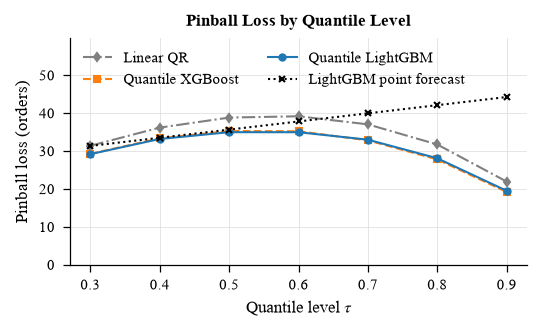

In [15]:
styles = {
    'Linear QR': dict(color='grey', linestyle='-.', marker='d'),
    'XGBoost': dict(color='tab:orange', linestyle='--', marker='s'),
    'LightGBM': dict(color='tab:blue', linestyle='-', marker='o'),
    'LightGBM point': dict(color='black', linestyle=':', marker='x'),
}
labels = {'Linear QR': 'Linear QR', 'XGBoost': 'Quantile XGBoost', 'LightGBM': 'Quantile LightGBM',
          'LightGBM point': 'LightGBM point forecast'}

plot_table = pinball_table.drop('mean')
fig, ax = plt.subplots(figsize=(ONE_COL, 2.1))
for name in model_order:
    ax.plot(plot_table.index, plot_table[name], markersize=3, label=labels[name], **styles[name])
ax.set_title('Pinball Loss by Quantile Level')
ax.set_xlabel(r'Quantile level $\tau$')
ax.set_ylabel('Pinball loss (orders)')
ax.set_xticks(TAUS)
ax.set_ylim(0, plot_table.values.max() * 1.35)
ax.legend(ncol=2, loc='upper left')
save_fig(fig, 'fig26_pinball_by_tau')
plt.show()

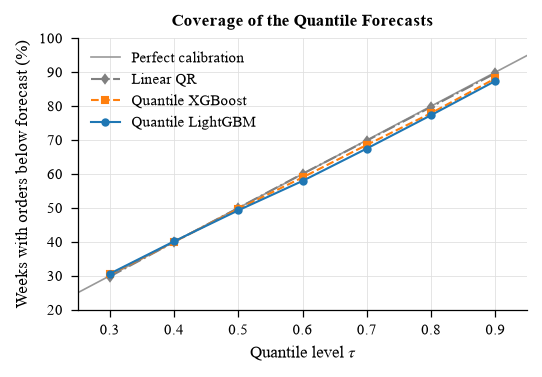

In [16]:
fig, ax = plt.subplots(figsize=(ONE_COL, 2.4))
ax.plot([0.25, 0.95], [25, 95], color='#999999', linewidth=0.8, label='Perfect calibration')
for name in q_models:
    ax.plot(coverage_table.index, coverage_table[name], markersize=3, label=labels[name], **styles[name])
ax.set_title('Coverage of the Quantile Forecasts')
ax.set_xlabel(r'Quantile level $\tau$')
ax.set_ylabel('Weeks with orders below forecast (%)')
ax.set_xticks(TAUS)
ax.set_xlim(0.25, 0.95)
ax.set_ylim(20, 100)
ax.legend(loc='upper left')
save_fig(fig, 'fig27_quantile_coverage')
plt.show()

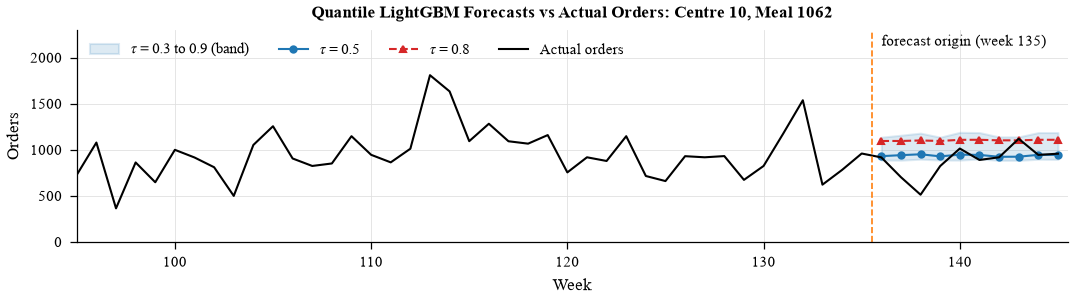

In [17]:
example_id = 101062      # the same series as figure 25
actual = df[df['series_id'] == example_id].set_index('week')['num_orders']
fc = qpred[(qpred['series_id'] == example_id) & (qpred['origin'] == 135)].set_index('week')

fig, ax = plt.subplots(figsize=(TWO_COL, 2.0))
ax.fill_between(fc.index, fc['LightGBM q0.3'], fc['LightGBM q0.9'], color='tab:blue', alpha=0.15,
                label=r'$\tau$ = 0.3 to 0.9 (band)')
ax.plot(fc.index, fc['LightGBM q0.5'], color='tab:blue', marker='o', markersize=3, label=r'$\tau$ = 0.5')
ax.plot(fc.index, fc['LightGBM q0.8'], color='tab:red', linestyle='--', marker='^', markersize=3, label=r'$\tau$ = 0.8')
ax.plot(actual.loc[95:].index, actual.loc[95:].values, color='black', linewidth=1, label='Actual orders')
ax.axvline(135.5, color='tab:orange', linestyle='--', linewidth=0.8)
ax.text(136, 2250, 'forecast origin (week 135)', ha='left', va='top', fontsize=7)
ax.set_title('Quantile LightGBM Forecasts vs Actual Orders: Centre 10, Meal 1062')
ax.set_xlabel('Week')
ax.set_ylabel('Orders')
ax.set_xlim(95, 145.5)
ax.set_ylim(0, 2300)
ax.legend(ncol=4, loc='upper left')
save_fig(fig, 'fig28_example_quantiles')
plt.show()

## 5. Save

In [18]:
qres.to_csv('../results/tables/06_quantile_results_per_fold.csv', index=False)
pinball_table.round(3).to_csv('../results/tables/06_pinball_mean.csv')
coverage_table.round(2).to_csv('../results/tables/06_coverage_mean.csv')
dm_table.to_csv('../results/tables/06_diebold_mariano.csv', index=False)
median_table.round(3).to_csv('../results/tables/06_median_as_point_forecast.csv')
print('saved')

saved


## Summary

| Model | Mean pinball loss (7 levels) | Distance from target coverage | Rows with crossing (before sorting) |
|---|---|---|---|
| Linear QR | 33.78 | 0.15 points | 0% |
| Quantile XGBoost | 30.44 | 1.0 points | 0% |
| **Quantile LightGBM** | **30.44** | 1.6 points | 24-28% |
| LightGBM point forecast (reference) | 37.83 | - | - |

**RQ2 answer: yes.**
- Quantile LightGBM has a 19.5% lower pinball loss than the point forecast (33% lower at $\tau$ = 0.8,
  56% at $\tau$ = 0.9, p < 0.001).
- The tree models are about 10% better than Linear QR. LightGBM and XGBoost are equal.
- Coverage is close to the target: 77-80% for $\tau$ = 0.8.
- LightGBM forecasts crossed in about a quarter of the rows (fixed by sorting). XGBoost had no crossing.
- Quantile LightGBM at $\tau$ = 0.5 is also a slightly better point forecast (WAPE 28.1% vs 28.65%).

Quantile LightGBM is the main model in the simulation (notebook 07).